# Idea básica de la Regresión Lineal Simple

## 1. Aclaraciones iniciales

1. Nos enfocaremos en datos tabulares pues para Series de Tiempo la Regresión Lineal tiene algunas particularidades.
2. A pesar de su simplicidad, los métodos de Regresión Lineal permiten abordar y resolver muchos problemas de negocio usando Ciencia de Datos.
3. Estos métodos son esenciales en la caja de herramientas de cualquier Científico de Datos y de hecho son la base para entender métodos, algoritmos y modelos de Machine Learning más complejos.

## 2. Ejemplo de motivación

In [5]:
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("ggplot")
import matplotlib as mpl
from cycler import cycler
mpl.rcParams['axes.prop_cycle'] = cycler(color=["#000000", "#000000"])
plt.rcParams.update({
    "figure.figsize": (12, 4),
    "figure.constrained_layout.use": True,
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "legend.title_fontsize": 10,
})


Usaremos el set de datos "publicidad.csv" que contiene datos de la cantidad de productos vendidos (en miles de unidades) así como los presupuestos de inversión (en miles de dólares) en diferentes medios (TV, radio, impreso):

In [4]:
# Leer dataset
df = pd.read_csv(f".\data\publicidad.csv")
df

,TV,radio,impreso,ventas
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9
...,...,...,...,...
195,38.2,3.7,13.8,7.6
196,94.2,4.9,8.1,9.7
197,177.0,9.3,6.4,12.8
198,283.6,42.0,66.2,25.5


Hagamos gráficos de dispersión para comparar las ventas (eje vertical) con los diferentes niveles de inversión en publicidad:

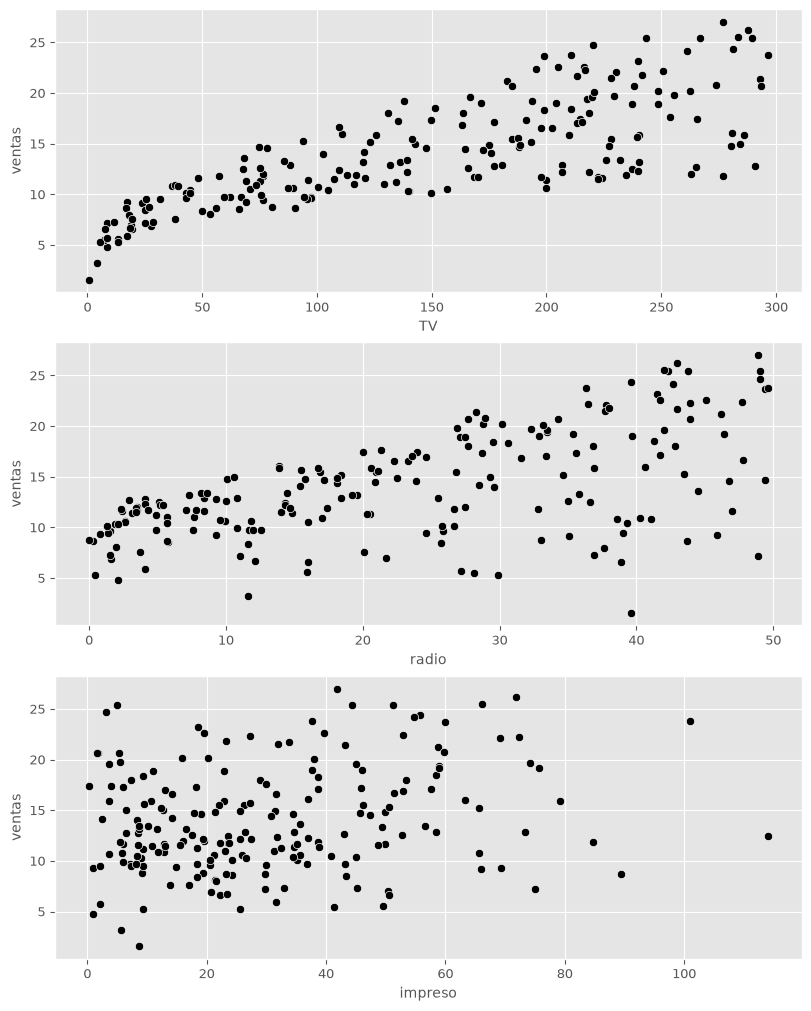

In [6]:
# Gráficos ventas vs. TV, radio, impreso
fig, axs = plt.subplots(3,1,figsize=(8,10))

for ax, col in zip(axs, ["TV", "radio", "impreso"]):
    sns.scatterplot(df, x=col, y="ventas", ax=ax)

Y ahora superpongamos a estos gráficos una línea recta (recta de regresión):

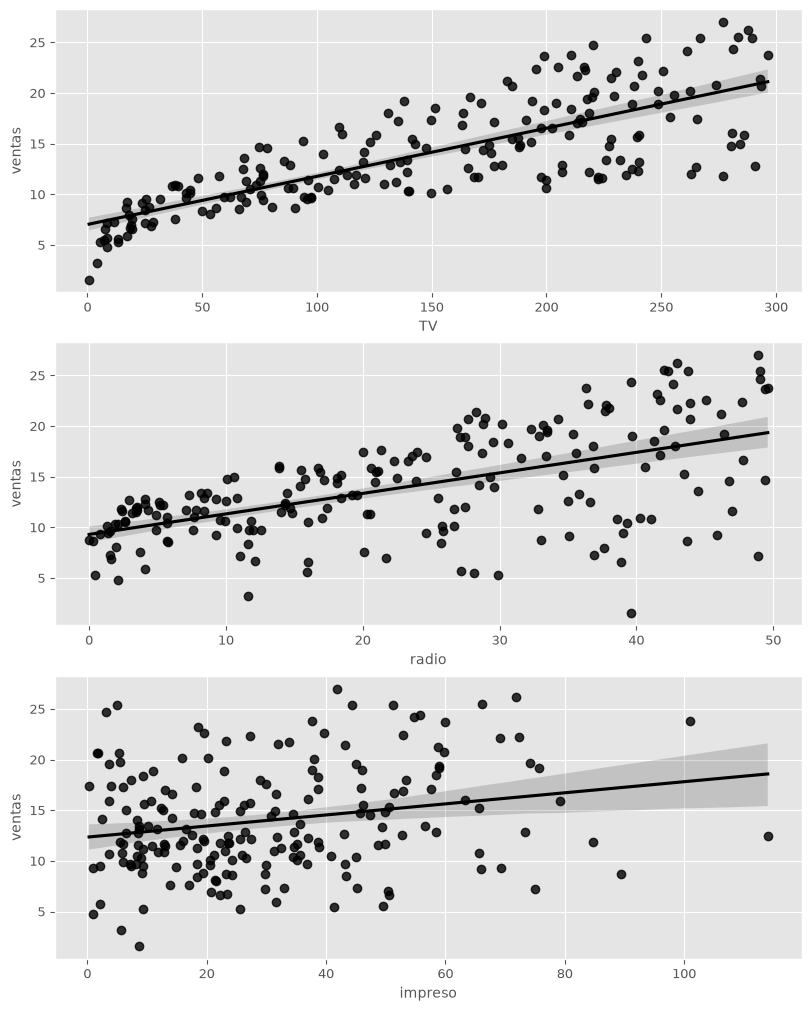

In [7]:
# Regplots
fig, axs = plt.subplots(3,1,figsize=(8,10))

for ax, col in zip(axs, ["TV", "radio", "impreso"]):
    sns.regplot(df, x=col, y="ventas", ax=ax)

Preguntas de motivación (que interesan al negocio):

1. ¿Hay relación (no causalidad) entre el nivel de publicidad y las ventas?
2. ¿Qué tan fuerte es la relación entre el nivel de publicidad y las ventas?
3. ¿Cuál de los tres tipos de publicidad contribuye más a las ventas?
4. ¿Por cada dolar invertido en publicidad (en cada medio) cuál es el incremento en las ventas?
5. ¿Qué precisión tendremos al intentar pronosticar las ventas?
6. ¿Existe una relación lineal entre la inversión en publicidad y las ventas?
7. ¿Cómo deberíamos destinar la inversión con el fin de incrementar las ventas? Es decir, ¿qué proporción deberíamos asignar a TV, radio e impreso?

**!La respuesta a todo esto está en la Regresión Lineal!**

## 2. La Regresión Lineal Simple

### 2.1. Idea básica y terminología

> El objetivo de la Regresión Lineal Simple es **predecir el valor de una variable numérica $y$ con base en el valor de una única variable numérica $x$**

![](.\images\idea_basica_regresion_lineal.png)

Terminología:

- $y$: variable a predecir
- $x$: variable predictora, covariable, *feature*
- $\hat{y}$: predicción hecha por el modelo

Ejemplos:

- $y$: ventas
- $x$: puede ser inversión publicitaria en **uno** de estos medios: TV, radio o impreso
- $\hat{y}$: nivel de ventas predicho por el modelo

### 2.2. Formalización matemática

1. Si las variables $y$ y $x$ tienen una relación lineal, podemos expresar esta relación matemáticamente como:

$$y = \beta_0 + \beta_1 x + \varepsilon$$

donde:

   - $\beta_0$ y $\beta_1$ son los **parámetros del modelo** (intercepto y pendiente)
   - $\varepsilon_t$ es un elemento **intrínseco de $y$ que no es capturado por el modelo**
   
2. Así, el modelo de Regresión Lineal simple tendrá esta forma:

$$\hat{y} = \beta_0 + \beta_1 x$$

donde $\hat{y}$ es la **predicción obtenida con el modelo** (que idealmente debería aproximarse a $y$)

Para el ejemplo particular que venimos analizando, podríamos construir modelos como estos:

$$\hat{\text{ventas}} = \beta_0 + \beta_1 \cdot \text{TV}$$
$$\hat{\text{ventas}} = \beta_0 + \beta_1 \cdot \text{radio}$$
$$\hat{\text{ventas}} = \beta_0 + \beta_1 \cdot \text{impreso}$$

donde en cada caso los parámetros del modelo ($\beta_0$, $\beta_1$) serán diferentes pues estaremos relacionando diferentes variables.

### 2.3. El objetivo final

> Encontrar automáticamente los parámetros del modelo ($\beta_0$, $\beta_1$) con base en los datos.